# Simple street canyon: moving vehicles

The example uses Sionna's built-in empty street canyon. Put the two i-MiEV PLY files in `examples/outdoor/meshes/` and run from the repository root or the notebook folder.

RX1 is stationary and RX2 rides on the third car. The default run uses the first ten snapshots (0–0.45 s); the trajectories cover 0–6 s.

Optional frame rendering is disabled by default. Enable it before creating a video with FFmpeg.

In [1]:
from pathlib import Path
import os, ctypes, sys
os.environ['CUDA_VISIBLE_DEVICES'] = ''
llvm = Path(os.environ.get('DRJIT_LIBLLVM_PATH') or (Path(sys.prefix) / 'lib/libLLVM.dylib'))
if llvm.is_file():
    os.environ['DRJIT_LIBLLVM_PATH'] = str(llvm)
    llvm_handle = ctypes.CDLL(str(llvm))

import numpy as np
import tensorflow as tf
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera

tf.random.set_seed(1)

In [58]:
all_paths = []
all_cir = []
snapshot_ids = []

In [59]:
from pathlib import Path

import mitsuba as mi
from sionna.rt import SceneObject, load_scene
from sionna.rt import scene as rt_scene

dtype = tf.complex64
rdtype = tf.float32

scene_dir = Path(rt_scene.__file__).resolve().parent / "scenes"
env_xml = scene_dir / "simple_street_canyon" / "simple_street_canyon.xml"

example_dir = Path("examples/outdoor")
if not example_dir.is_dir():
    example_dir = Path(".")
mesh_dir = example_dir.resolve() / "meshes"

scene = load_scene(str(env_xml), dtype=dtype)
T = mi.ScalarTransform4f

parts = [
    ("body", "i_miev_600_windowed-itu_metal.ply", scene.get("itu_metal")),
    ("glass", "i_miev_600_windowed-itu_glass.ply", scene.get("itu_glass")),
]

part_colors = {
    "body": [0.75, 0.06, 0.04],
    "glass": [0.04, 0.12, 0.23],
}

for _, filename, _ in parts:
    if not (mesh_dir / filename).is_file():
        raise FileNotFoundError(f"Place the car meshes in {mesh_dir}: missing {filename}")

body_mesh = mi.load_dict({"type": "ply", "filename": str(mesh_dir / parts[0][1])})
body_center = body_mesh.bbox().center()
body_center = np.array([float(body_center.x), float(body_center.y), float(body_center.z)])

car_z = 0.7  # Height of the body center (m).
turn_center = np.array([-12.0, -10.0])
turn_radius = 8.0
turn_start_deg = 30.0
turn_start = np.deg2rad(turn_start_deg)

spawn_origins = {
    "car_1": [turn_center[0] - turn_radius * np.cos(turn_start),
              turn_center[1] + turn_radius * np.sin(turn_start), car_z],
    "car_2": [-26.0, 27.0, car_z],
    "car_3": [-26.0, -12.0, car_z],
}

cars = []
car_parts = {}

# The unrotated i-MiEV faces -X.
for car_name, yaw_deg in [
    ("car_1", -90.0 - turn_start_deg),
    ("car_2", 90.0),
    ("car_3", 90.0),
]:
    position = spawn_origins[car_name]
    transform = (T.translate(position) @ T.rotate([0, 0, 1], yaw_deg)
                 @ T.translate((-body_center).tolist()))
    car_parts[car_name] = []

    for part, filename, material in parts:
        name = f"{car_name}_{part}"
        mesh = mi.load_dict({
            "type": "ply",
            "id": name,
            "filename": str(mesh_dir / filename),
            "to_world": transform,
            "face_normals": True,
            "bsdf": {
                "type": "diffuse",
                "reflectance": {"type": "rgb", "value": part_colors[part]},
            },
        })
        obj = SceneObject(
            name=name, scene=scene, mi_shape=mesh, radio_material=material
        )
        cars.append(obj)
        car_parts[car_name].append(obj)

scene.edit(add=cars)
obj_names = [obj.name for obj in cars]

num_edges: tf.Tensor(4, shape=(), dtype=int32)
num_wedges: 76
num_edges: tf.Tensor(4, shape=(), dtype=int32)
num_wedges: 3607


In [60]:
# scene.preview()

In [ ]:
from pathlib import Path

render_dir = Path("pics")
use_motion = True
save_results = False

render_frames = False
make_video = False

# Enable wall-to-car and car-to-wall paths: wall reflection combined with
# reflection, wedge diffraction, or vertex diffraction on the car.
# These echoes can appear as ghost targets.
target_2nd_order_paths = False

idx = 0
num_snapshots = 10

In [62]:
import numpy as np

delta_t = 0.05
t = np.arange(121) * delta_t


def car_a(t, speed=8.0):
    # Start on the right turn, then continue east.
    s = speed * np.asarray(t)
    arc_length = turn_radius * (np.pi / 2 - turn_start)
    angle = turn_start + np.minimum(s, arc_length) / turn_radius

    x = turn_center[0] - turn_radius * np.cos(angle) + np.maximum(s - arc_length, 0)
    y = turn_center[1] + turn_radius * np.sin(angle)
    position = np.stack([x, y, np.full_like(x, car_z)], axis=-1)

    vx = speed * np.sin(angle)
    vy = speed * np.cos(angle)
    velocity = np.stack([vx, vy, np.zeros_like(vx)], axis=-1)
    yaw = np.pi / 2 - angle
    return position, velocity, yaw


def car_b(t, speed=7.0):
    t = np.asarray(t)
    velocity = np.broadcast_to([0.0, -speed, 0.0], (len(t), 3)).copy()
    position = np.asarray(spawn_origins["car_2"]) + t[:, None] * velocity
    yaw = np.full_like(t, -np.pi / 2)
    return position, velocity, yaw


pos_a, vel_a, yaw_a = car_a(t)
pos_b, vel_b, yaw_b = car_b(t)

vel_c = np.tile([0.0, -3.0, 0.0], (len(t), 1))
pos_c = np.asarray(spawn_origins["car_3"]) + t[:, None] * vel_c

In [63]:
tx_pos = np.array([18.7, 4.5, 1.5])

rx2_offset = np.array([0.0, 0.0, 1.5 - pos_c[0, 2]])

rx_positions = np.stack([
    [-17.5, -17.3, 4.5],  # RX1: stationary
    pos_c[0] + rx2_offset,  # RX2: 1.5 m above ground
])

tx_velocities = np.zeros((1, 3))
rx_velocities = np.zeros_like(rx_positions)

In [64]:
moving_car_names = ["car_1", "car_2", "car_3"]

In [65]:
scene.tx_array = PlanarArray(num_rows=1,
							 num_cols=1,
							 vertical_spacing=0.5,
							 horizontal_spacing=0.5,
							 pattern="iso",
							 polarization="V",
							 dtype=dtype)

scene.rx_array = scene.tx_array

fc = 5.9e9
lamda = 3e8 / fc

scene.frequency = fc
scene.synthetic_array = True 

In [66]:
obj_names

['car_1_body',
 'car_1_glass',
 'car_2_body',
 'car_2_glass',
 'car_3_body',
 'car_3_glass']

In [67]:
def set_tx_rxs(scene, tx_radius=2.0, rx_radius=1.3):
    for name in list(scene.transmitters) + list(scene.receivers):
        scene.remove(name)

    tx = Transmitter(name="tx", position=tx_pos, dtype=dtype)
    tx.display_radius = tx_radius
    scene.add(tx)

    for i, rx_pos in enumerate(rx_positions, start=1):
        rx = Receiver(name=f"rx_{i}", position=rx_pos, dtype=dtype)
        rx.display_radius = rx_radius
        scene.add(rx)


set_tx_rxs(scene)

In [68]:
from sionna.rt.objects_geometry import ObjectsGeometry

obj_geom = ObjectsGeometry(scene._solver_paths)
obj_geom.is_vertex_diffraction = True
obj_geom.is_double_diffraction = False

obj_geom.enable_env_object_rr = target_2nd_order_paths
obj_geom.enable_env_object_rwd = target_2nd_order_paths
obj_geom.enable_env_object_rvd = target_2nd_order_paths

obj_files = [None] * len(obj_names)
obj_geom.init_objects(obj_names, obj_files)

scene._solver_paths.vertex_diffraction.set_objects_geometry(obj_geom)

Removed 744 duplicate vertex-wedge contributions.
num vertices: 1644


In [69]:
for k, v in scene.radio_materials.items():
	if k not in ['itu_metal', 'itu_glass']:
		v.scattering_coefficient = 0.7

In [70]:
from sionna.rt.utils import mi_to_tf_tensor, rotation_matrix

rdtype = scene.dtype.real_dtype

# Capture once, after scene.edit(add=cars) and before moving the cars.
base_vertices = {}
params = scene.mi_scene_params

for name in moving_car_names:
    # Use the same pivot for the body and glass as in the initial transform.
    origin = tf.cast(spawn_origins[name], rdtype)

    for obj in car_parts[name]:
        key = f"{obj.mi_shape.id()}.vertex_positions"
        vertices = tf.reshape(mi_to_tf_tensor(params[key], rdtype), [-1, 3])
        base_vertices[obj.name] = vertices - origin


def update_moving_cars(i):
    positions = [pos_a[i], pos_b[i], pos_c[i]]
    velocities = [vel_a[i], vel_b[i], vel_c[i]]
    yaws = [yaw_a[i] - yaw_a[0], yaw_b[i] - yaw_b[0], 0.0]

    updates = []
    for name, position, velocity, yaw in zip(
        moving_car_names, positions, velocities, yaws
    ):
        rotation = rotation_matrix(tf.constant([yaw, 0.0, 0.0], dtype=rdtype))
        position = tf.cast(position, rdtype)

        for obj in car_parts[name]:
            vertices = base_vertices[obj.name] @ tf.transpose(rotation) + position
            obj.velocity = velocity
            updates.append((obj, vertices))

    # Refresh Mitsuba and diffraction geometry once per snapshot.
    for j, (obj, vertices) in enumerate(updates):
        obj._set_mesh_vertices(vertices, is_update=(j == len(updates) - 1))

    rx_positions[1] = pos_c[i] + rx2_offset
    scene.receivers["rx_2"].position = rx_positions[1]
    rx_velocities[1] = vel_c[i]

In [71]:
link_names = [f"tx → {name}" for name in scene.receivers]
link_names

['tx → rx_1', 'tx → rx_2']

In [54]:
# update_moving_cars(0)
# scene.preview()

In [72]:
if use_motion and not (0 <= idx < idx + num_snapshots <= len(t)):
    raise ValueError("Requested snapshots exceed the available trajectories.")

for i in range(idx, idx + num_snapshots):
    if use_motion:
        update_moving_cars(i)

    paths = scene.compute_paths(
        max_depth=3,
        method="fibonacci",
        num_samples=10**5,
        los=True,
        reflection=True,
        scattering=True,
        scat_keep_prob=1.0,
        scat_sparsity_coef=100,
        scat_random_phases=False,
        diffraction=True,
        refl_diff=False,
        double_diffraction=False,
        vertex_diffraction=True,
    )
    paths.normalize_delays = False
    a, tau = paths.cir()
    doppler = paths._get_doppler(tx_velocities=tx_velocities, rx_velocities=rx_velocities)
    all_paths.append(paths.to_dict())
    all_cir.append((np.asarray(a), np.asarray(tau), np.asarray(doppler),
                    np.asarray(paths.mask)))
    snapshot_ids.append(i)

    if i % 10 == 0:
        print("Snapshot:", i)
    if render_frames:
        render_dir.mkdir(parents=True, exist_ok=True)
        camera = Camera("my_cam", position=[-25, -35, 150], look_at=[-19, -4, 0])
        scene.add(camera)
        try:
            scene.render_to_file(camera="my_cam",
                                 filename=str(render_dir / f"env_{i:03d}.png"),
                                 resolution=[1000, 800], num_samples=15)
        finally:
            scene.remove("my_cam")

Snapshot: 0
Snapshot: 10
Snapshot: 20
Snapshot: 30
Snapshot: 40
Snapshot: 50
Snapshot: 60
Snapshot: 70
Snapshot: 80
Snapshot: 90
Snapshot: 100
Snapshot: 110
Snapshot: 120


In [57]:
# new_paths = paths.gather_targets([0])
# scene.preview(new_paths)

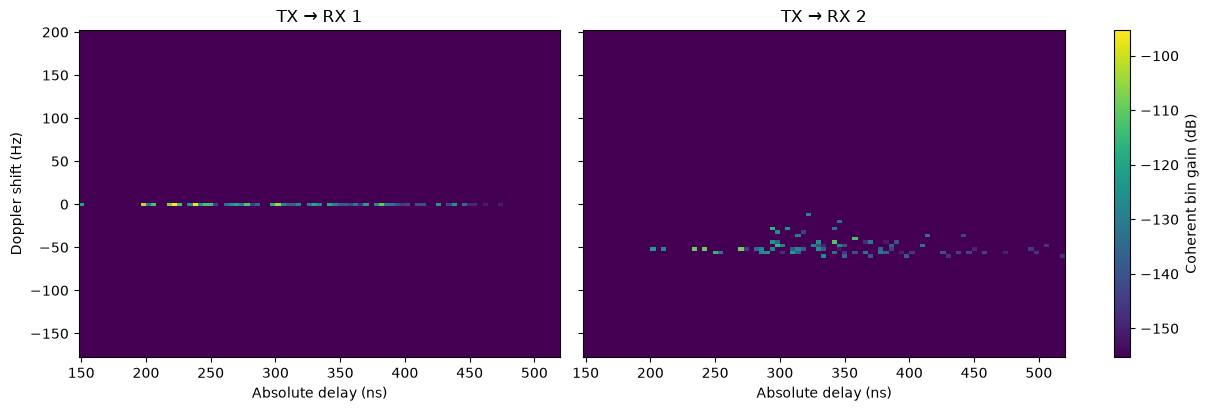

In [73]:
import numpy as np
import matplotlib.pyplot as plt

snapshot = -1
delay_bin_ns = 4.0
doppler_bin_hz = 4.0
dynamic_range_db = 60.0

noise_floor_db = -180.0  # Mean noise power per bin; None disables noise.
rng = np.random.default_rng(42)

if not all_cir:
    raise ValueError("Run at least one snapshot first.")


def snapshot_links(frame):
    a_f, tau_f, doppler_f, mask_f = frame

    amp = a_f[0, :, 0, 0, 0, :, 0]
    delay_ns = tau_f[0, :, 0, :] * 1e9
    doppler_hz = doppler_f[0, :, 0, 0, 0, :, 0]

    good = (
        mask_f[0, :, 0, :]
        & np.isfinite(amp)
        & np.isfinite(delay_ns)
        & np.isfinite(doppler_hz)
    )

    return [
        (amp[rx, valid], delay_ns[rx, valid], doppler_hz[rx, valid])
        for rx, valid in enumerate(good)
    ]


def bin_edges(values, step, center_offset=0.0):
    first = int(np.floor((values.min() - center_offset) / step))
    last = int(np.floor((values.max() - center_offset) / step))
    return center_offset + step * np.arange(first, last + 2)


# Build one grid shared by all snapshots and receivers.
delays, dopplers = [], []
for frame in all_cir:
    for _, delay_ns, doppler_hz in snapshot_links(frame):
        delays.append(delay_ns)
        dopplers.append(doppler_hz)

all_delays = np.concatenate(delays)
all_dopplers = np.concatenate(dopplers)
if all_delays.size == 0:
    raise ValueError("No valid paths in any snapshot.")

delay_edges = bin_edges(all_delays, delay_bin_ns)
doppler_edges = bin_edges(all_dopplers, doppler_bin_hz, -doppler_bin_hz / 2)

# Plot only the selected snapshot on the shared grid.
links = snapshot_links(all_cir[snapshot])
n_rx = len(links)
maps = []

for amp, delay_ns, doppler_hz in links:
    delay_idx = np.searchsorted(delay_edges, delay_ns, side="right") - 1
    doppler_idx = np.searchsorted(doppler_edges, doppler_hz, side="right") - 1

    field = np.zeros(
        (len(doppler_edges) - 1, len(delay_edges) - 1),
        dtype=np.complex128,
    )
    np.add.at(field, (doppler_idx, delay_idx), amp)

    if noise_floor_db is not None:
        sigma = np.sqrt(10.0 ** (noise_floor_db / 10.0) / 2.0)
        field += sigma * (
            rng.standard_normal(field.shape) + 1j * rng.standard_normal(field.shape)
        )

    maps.append(np.abs(field) ** 2)

peak_db = 10 * np.log10(max(max(power.max() for power in maps), 1e-30))

fig, axes = plt.subplots(
    1, n_rx, figsize=(6 * n_rx, 4), sharex=True, sharey=True,
    squeeze=False, layout="constrained",
)

for rx, (ax, power) in enumerate(zip(axes[0], maps)):
    power_db = 10 * np.log10(np.maximum(power, 1e-30))
    mesh = ax.pcolormesh(
        delay_edges, doppler_edges, np.ma.masked_where(power == 0, power_db),
        cmap="viridis", vmin=peak_db - dynamic_range_db, vmax=peak_db,
        shading="flat",
    )
    ax.set(title=f"TX → RX {rx + 1}", xlabel="Absolute delay (ns)")

axes[0, 0].set_ylabel("Doppler shift (Hz)")
fig.colorbar(mesh, ax=axes[0].tolist(), label="Coherent bin gain (dB)")
plt.show()

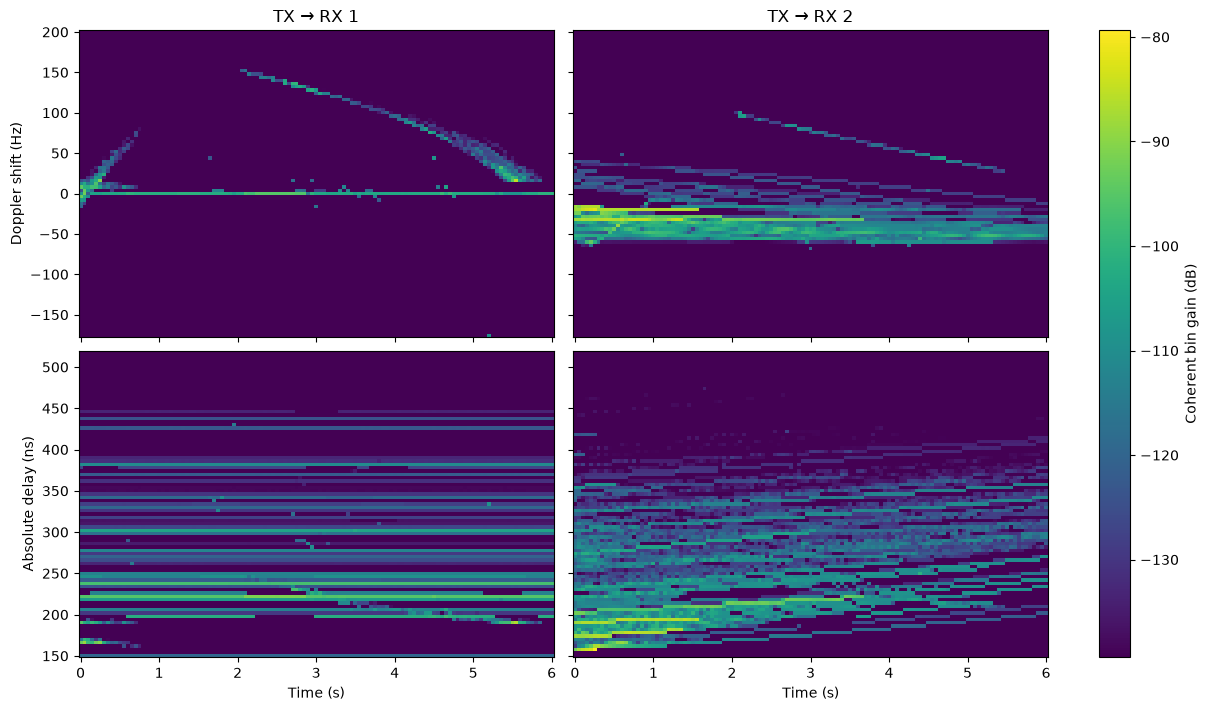

In [74]:
if not all_cir:
    raise ValueError("Run at least one snapshot first.")

n_frames = len(all_cir)
n_rx = all_cir[0][0].shape[1]

frame_ids = np.asarray(snapshot_ids)
if len(frame_ids) != n_frames or np.any(np.diff(frame_ids) != 1):
    raise ValueError("These plots expect contiguous snapshots. Reset the stored results before rerunning.")
time_edges = (frame_ids[0] + np.arange(n_frames + 1) - 0.5) * delta_t

rows = [
    (doppler_edges, "Doppler shift (Hz)"),
    (delay_edges, "Absolute delay (ns)"),
]
power_maps = [
    np.zeros((n_rx, len(edges) - 1, n_frames))
    for edges, _ in rows
]
outside = np.zeros((len(rows), n_rx), dtype=int)

for j, (a_f, tau_f, doppler_f, mask_f) in enumerate(all_cir):
    for rx in range(n_rx):
        valid = mask_f[0, rx, 0, :]
        amp = a_f[0, rx, 0, 0, 0, :, 0][valid]
        doppler = doppler_f[0, rx, 0, 0, 0, :, 0][valid]
        delay_ns = tau_f[0, rx, 0, :][valid] * 1e9

        for row, values in enumerate((doppler, delay_ns)):
            edges, _ = rows[row]
            finite = np.isfinite(amp) & np.isfinite(values)
            inside = finite & (values >= edges[0]) & (values <= edges[-1])
            outside[row, rx] += np.count_nonzero(finite & ~inside)

            bins = np.searchsorted(edges, values[inside], side="right") - 1
            bins = np.minimum(bins, len(edges) - 2)  # Include the rightmost edge.
            field = np.zeros(len(edges) - 1, dtype=np.complex128)

            np.add.at(field, bins, amp[inside])

            if noise_floor_db is not None:
                noise_power = 10.0 ** (noise_floor_db / 10.0)
                sigma = np.sqrt(noise_power / 2.0)
                field += sigma * (
                    rng.standard_normal(field.shape)
                    + 1j * rng.standard_normal(field.shape)
                )

            power_maps[row][rx, :, j] = np.abs(field) ** 2

peak_db = 10 * np.log10(max(max(p.max() for p in power_maps), 1e-30))
fig, axes = plt.subplots(
    2, n_rx, figsize=(6 * n_rx, 7),
    sharex=True, sharey="row", squeeze=False, layout="constrained",
)

for row, (edges, ylabel) in enumerate(rows):
    for rx, ax in enumerate(axes[row]):
        power = power_maps[row][rx]
        gain_db = 10 * np.log10(np.maximum(power, 1e-30))
        mesh = ax.pcolormesh(
            time_edges, edges, np.ma.masked_where(power == 0, gain_db),
            shading="flat", cmap="viridis",
            vmin=peak_db - dynamic_range_db, vmax=peak_db,
        )
        if row == 0:
            ax.set_title(f"TX → RX {rx + 1}")
        else:
            ax.set_xlabel("Time (s)")
    axes[row, 0].set_ylabel(ylabel)

fig.colorbar(mesh, ax=axes.ravel().tolist(), label="Coherent bin gain (dB)")
plt.show()

for row, (_, label) in enumerate(rows):
    for rx, count in enumerate(outside[row]):
        if count:
            print(f"RX {rx + 1}, {label}: {count} paths outside the grid")

In [75]:
if save_results:
    import pickle

    output_dir = Path("paths")
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "paths.pkl").open("wb") as f:
        pickle.dump(all_paths, f)
    with (output_dir / "cir.pkl").open("wb") as f:
        pickle.dump(all_cir, f)
    with (output_dir / "obj_geom.pkl").open("wb") as f:
        pickle.dump(obj_geom.to_dict(), f)

In [77]:
if make_video:
    import subprocess

    subprocess.run([
        "ffmpeg", "-y", "-framerate", str(round(1 / delta_t)),
        "-pattern_type", "glob", "-i", str(render_dir / "env_*.png"),
        "-pix_fmt", "yuv420p", str(render_dir / "street_canyon.mp4"),
    ], check=True)

ffmpeg version 5.1 Copyright (c) 2000-2022 the FFmpeg developers
  built with clang version 13.0.1
  configuration: --prefix=/Users/ainur/miniforge3/envs/v0_sionna_public --cc=arm64-apple-darwin20.0.0-clang --cxx=arm64-apple-darwin20.0.0-clang++ --nm=arm64-apple-darwin20.0.0-nm --ar=arm64-apple-darwin20.0.0-ar --disable-doc --disable-openssl --enable-demuxer=dash --enable-hardcoded-tables --enable-libfreetype --enable-libfontconfig --enable-libopenh264 --enable-cross-compile --arch=arm64 --target-os=darwin --cross-prefix=arm64-apple-darwin20.0.0- --host-cc=/Users/runner/miniforge3/conda-bld/ffmpeg_1660333894386/_build_env/bin/x86_64-apple-darwin13.4.0-clang --enable-neon --enable-gnutls --enable-libmp3lame --enable-libvpx --enable-pthreads --enable-gpl --enable-libx264 --enable-libx265 --enable-libaom --enable-libsvtav1 --enable-libxml2 --enable-pic --enable-shared --disable-static --enable-version3 --enable-zlib --pkg-config=/Users/runner/miniforge3/conda-bld/ffmpeg_1660333894386/_bui